# Combined DAS Event Analysis

Compares SNR-enhancement methods for the humpback, Bigg's and SRKW (J pod) events:

1. Reference channel
2. Loop stacking
3. Stacking after MBS (median background subtraction)
4. Stacking and NES (noise envelope subtraction)
5. Beamforming after MBS

In [2]:
import os
import h5py
import numpy as np
import scipy.signal as sp
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as ticker
import pandas as pd
import gc
from IPython.display import display, Audio
from datetime import datetime
from scipy.signal import stft, istft, detrend, hilbert

from das_functions import *
from noise_env_sub import compute_snr_hat, enhance_tonal_signals

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [3]:
current_event = "jpod jan"  # 'humpback', 'biggs', 'jpod jan'

In [4]:
# ==============================================================================
# EVENT SELECTION & CONFIGURATION
# ==============================================================================

## --- Biggs ---
# current_event = "Biggs"
# fdir = "/mnt/haro_fs/" 
# flist_source = ['decimator_2026-01-02_23.43.00_UTC_097029.h5']
# flist_noise = ['decimator_2026-01-02_23.40.00_UTC_097026.h5']
# t_win = (24.5, 25.1)        # Target window for peak SNR (s)
# f_win = (950, 1600)         # Target window for peak SNR (Hz)
# t_plot_lim = (12, 28)       # Time range for spectrogram plots (s)
# loop_num = 1 
# c_ref_offset = 3
# event_name_bf = "biggs"
# beam_loops = [1, 2]
# sig_band = [900, 2499]      # Signal band for NES
# noise_band1 = [1, 899]      # Noise band for NES
# noise_band2 = None
# t_start = 12
# t_end = 27
# vmin, vmax = 0, 20



# ## jpod
fdir = "/mnt/haro_fs/" 
flist_source = ['decimator_2026-01-23_21.37.00_UTC_126890.h5']
flist_noise = ['decimator_2026-01-23_21.30.00_UTC_126883.h5']
# jpod
t_win = (7, 8)        # seconds
f_win = (920, 1050)    # Hz
# ref_offset = 4
loop_num = 2
c_ref = 49
# flist_source = ['decimator_2026-01-23_21.36.00_UTC_126889.h5']
event_name = "jpod jan"
beam_loops = [[2, 3]]
sig_band = [800, 2100]      # Signal band for NES
noise_band1 = [50, 800]      # Noise band for NES
noise_band2 = [2100, 2499]      # Noise band for NES
# noise_band2 = [2100, 2499]      # Noise band for NES
t_start = 0
t_end = 15
vmin, vmax = 0, 25

# #Jpod
# b_sig, a_sig = sp.butter(4, [800, 2100], btype="bandpass", fs=fs)

# b_n1, a_n1 = sp.butter(4, [50, 800], btype="bandpass", fs=fs)   
# b_n2, a_n2 = sp.butter(4, [2100, 2499], btype="bandpass", fs=fs)


# # # #Humpback
# current_event = "humpback"
# fdir = "/mnt/nas_das4orcas_onyx/haro-fs/" 
# flist_source = ['decimator_2025-11-14_09.33.00_UTC_049649.h5']
# #nbg decimator_2025-11-14_09.33.00_UTC_047252.h5
# # #flist_source = ['decimator_2025-11-14_09.39.00_UTC_049655.h5']
# flist_noise = ['decimator_2025-11-14_09.20.00_UTC_049636.h5']
# #nbg decimator_2025-11-14_09.20.00_UTC_047239.h5
# loop_num = 1
# c_ref_offset = 3
# sig_band = [300, 1549]      # Signal band for NES
# noise_band1 = [20, 300]      # Noise band for NES
# noise_band2 = [1550, 2499]      # Noise band for NES
# t_win = (56.5, 57.25)        # seconds
# f_win = (900, 1550)    # Hz
# loop_num = 1 
# # c_ref = 40
# beam_loops = [[1, 2]]
# t_start = 45
# t_end = 60
# t_plot_lim = (45,60) 
# vmin, vmax = 0, 25 

# =========================
# SHARED CALC CONFIG
# =========================
nperseg = 512
noverlap = int(nperseg * 0.8)
use_fibers = [1]     # Options: [1], [2], or [1, 2]
nes_gain_power = 1.0  # NES gain exponent (1.0 = linear subtraction)

noise_config = {
    "ref": "separate", "loop": "separate", "post_stack": "separate",
    "pre_stack": "separate", "hat_1d": "same", "hat_freq": "separate"
}

In [5]:
print(f"Analyzing {current_event}...")
meta = get_h5_metadata(os.path.join(fdir, flist_source[0]))
fs, dx, gl, ns, nx = meta['fs'], meta['dx'], meta['gl'], meta['ns'], meta['nx']
source_raw, _ = load_data(fdir, flist_source)
noise_raw, _ = load_data(fdir, flist_noise)
source = preprocess(source_raw, fs, lowcut=250)
noise_file = preprocess(noise_raw, fs, lowcut=250)

env_data = get_environmental_metadata(os.path.join(fdir, flist_source[0]))
if env_data:
    print(f"Tide Height: {env_data['tide_height']:.2f} m, Wind: {env_data['wind_speed']:.1f} km/h")

Analyzing jpod jan...


Tide Height: 1.20 m, Wind: nan km/h


In [6]:
fiber_length = 2000
loops_f1 = [(120, 142), (144, 203), (271, 296), (443, 465), (630, 660), (855, 887), (1091, 1123), (1659, 1722), (1821, 1879)]
loops_f2 = [(2 * fiber_length - L[1], 2 * fiber_length - L[0]) for L in loops_f1]
loops = []
for i in range(8):
    l_group = []
    if 1 in use_fibers: l_group.append(loops_f1[i])
    if 2 in use_fibers: l_group.append(loops_f2[i])
    loops.append(l_group)
loop_channels = [[(int(L[0] / dx), int(L[1] / dx)) for L in l_group] for l_group in loops]

c_group = loop_channels[loop_num - 1]
# c_ref may be set directly in the config cell instead of via c_ref_offset
if 'c_ref_offset' in globals():
    c_ref = c_group[0][0] + c_ref_offset
print(f"Reference Loop: {loop_num}, Ref Channel: {c_ref}")

def get_noise_ref(choice, chan_data):
    # 'separate' = noise-only file; 'same' = signal recording (time-aligned, used for NES)
    src = noise_file if choice == "separate" else source
    if chan_data is None:
        return [src[:, c0:c1] for c0, c1 in c_group]
    return src[:, chan_data]

sig_block = np.concatenate([source[:, c0:c1] for c0, c1 in c_group], axis=1)
sig_stack = np.mean(sig_block, axis=1)
n_block_list = get_noise_ref(noise_config["hat_1d"], None)
n_block_concat = np.concatenate(n_block_list, axis=1)
n_stack = np.mean(n_block_concat, axis=1)

Reference Loop: 2, Ref Channel: 49


In [7]:
beam_loops = [[2,3]]  # Example beamforming loops

In [8]:
# WHALE_DELAYS = {
#     "humpback": {
#         (0, 1): -136,(0, 2): -1573, (0, 3): 450, (0, 4): -15, (0, 5): 1037, (0, 6): 2571, (0, 7): 3107,
#         (1, 2): -136, (1, 3): 722, (1, 4): 893, (1, 5): 1083, (1, 6): 2639, (1, 7): 3171,
#         (2, 3): -971, (2, 4): 3079, (2, 5): 4448, (2, 6): 5978, (2, 7): -1079,
#         (3, 4): -1364, (3, 5): 656, (3, 6): 1392, (3, 7): 2429,
#         (4, 5): 1369, (4, 6): 3781, (4, 7): 2843,
#         (5, 6): 1538, (5, 7): 2079,
#         (6, 7): 518
#     },
# }

In [9]:
# # # ## Print Beamforming Delays
event_name = "jpod jan"  # 'humpback', 'biggs', 'jpod jan'
ref_loop_idx = 2    # 1-based index (e.g., 1 or 2)

#from das_functions import WHALE_DELAYS

delays = WHALE_DELAYS[event_name]
n_loops = len(loops)

print(f"--- Beamforming Delays for {event_name} (Ref Loop: {ref_loop_idx}) ---")
for i in range(1, n_loops + 1):
    if i == ref_loop_idx:
        shift = 0
    else:
        # The dictionary uses 0-based indices for internal storage (0 to 7)
        # We check both (ref, target) and (target, ref) with appropriate sign flip
        a, b = ref_loop_idx - 1, i - 1
        if (a, b) in delays:
            shift = delays[(a, b)]
        elif (b, a) in delays:
            shift = -delays[(b, a)]
        else:
            shift = "No delay found"
            
    print(f"Loop {i}: delay = {shift} samples")

--- Beamforming Delays for jpod jan (Ref Loop: 2) ---
Loop 1: delay = No delay found samples
Loop 2: delay = 0 samples
Loop 3: delay = 177 samples
Loop 4: delay = 2417 samples
Loop 5: delay = 1445 samples
Loop 6: delay = 1975 samples
Loop 7: delay = 2361 samples
Loop 8: delay = 2394 samples


In [10]:
print("Process (STFT -> Normalization -> ISTFT -> Spectrogram)...")

# 1. Setup Beamforming configuration robustly
if isinstance(beam_loops, list) and len(beam_loops) > 0 and isinstance(beam_loops[0], list):
    beam_loops_clean = beam_loops[0]
else:
    beam_loops_clean = beam_loops

ref_loop_idx = int(beam_loops_clean[0])
target_loops = [int(i) for i in beam_loops_clean[1:]]
bf_event = event_name.lower()

def get_enhanced_trace(tr, fs, nperseg, noverlap, mbs=True, bis=False):
    f_p, t_p, Zxx_p = stft(tr, fs=fs, nperseg=nperseg, noverlap=noverlap)
    S_log = 10 * np.log10(np.abs(Zxx_p)**2 + 1e-12)
    norm = np.zeros_like(S_log)
    if mbs:
        m_bg = np.nanmedian(S_log, axis=1, keepdims=True)
        norm += m_bg
        if bis:
            norm += np.nanmedian(S_log - m_bg, axis=0, keepdims=True)
    elif bis:
        norm += np.nanmedian(S_log, axis=0, keepdims=True)
    Zxx_norm = Zxx_p * 10**(-norm/20)
    _, tr_rec = istft(Zxx_norm, fs=fs, nperseg=nperseg, noverlap=noverlap)
    return tr_rec[:len(tr)]

def beamform_custom(data_dict, ref_idx, targets, event):
    from das_functions import WHALE_DELAYS
    event_key = event.lower()
    if event_key not in WHALE_DELAYS:
        print(f"Warning: No delays for {event_key}, using raw sum.")
        return np.sum([data_dict[i] for i in [ref_idx] + targets], axis=0)
    delays = WHALE_DELAYS[event_key]
    bf_sig = np.copy(data_dict[ref_idx]).astype(float)
    for i in targets:
        a, b = ref_idx - 1, i - 1
        shift = delays[(a, b)] if (a, b) in delays else (-delays[(b, a)] if (b, a) in delays else None)
        if shift is None:
            print(f"Warning: No delay for ({ref_idx}, {i})"); continue
        shifted = np.roll(data_dict[i], -shift)
        if shift > 0: shifted[-shift:] = 0
        elif shift < 0: shifted[:-shift] = 0
        print(f"Beamforming with reference loop {ref_idx} and targets {targets} for event '{event_key}'")
        bf_sig += shifted
    return bf_sig

# 2. Pre-calculate Loop Dictionaries (Raw and Enhanced)
data_dict_raw = {}; data_dict_enhanced = {}
print("Stacking")
for i in range(1, 9):
    c_group = loop_channels[i-1]
    data_dict_raw[i] = np.mean([np.mean(source[:, c0:c1], axis=1) for c0, c1 in c_group], axis=0)
    enhanced_fiber_stacks = []
    for c0, c1 in c_group:
        enhanced_channels = [get_enhanced_trace(source[:, c], fs, nperseg, noverlap, mbs=True, bis=True) for c in range(c0, c1)]
        enhanced_fiber_stacks.append(np.mean(enhanced_channels, axis=0))
    data_dict_enhanced[i] = np.mean(enhanced_fiber_stacks, axis=0)

# =========================================================
# 1. Reference Channel (MBS Time)
# =========================================================
tr1_enhanced = get_enhanced_trace(source[:, c_ref], fs, nperseg, noverlap, mbs=False, bis=False)
f1, t1, SNR1 = compute_snr_spectrogram(tr1_enhanced, np.ones((nperseg//2+1, 1)), fs, nperseg, noverlap)
SNR1 -= np.nanmedian(SNR1, axis=1, keepdims=True)

# =========================================================
# 2. Loop Stacked (MBS Pre-stack)
# =========================================================
tr2_enhanced = get_enhanced_trace(data_dict_raw[loop_num], fs, nperseg, noverlap, mbs=False, bis=False)
f2, t2, SNR2 = compute_snr_spectrogram(tr2_enhanced, np.ones((nperseg//2+1, 1)), fs, nperseg, noverlap)
SNR2 -= np.nanmedian(SNR2, axis=1, keepdims=True)

# =========================================================
# 3. Loop Stacked (BIS Post-stack)
# =========================================================
# tr3_enhanced = get_enhanced_trace(data_dict_raw[loop_num], fs, nperseg, noverlap, mbs=True, bis=True)
# f3, t3, SNR3 = compute_snr_spectrogram(tr3_enhanced, np.ones((nperseg//2+1, 1)), fs, nperseg, noverlap)
# SNR3 -= np.nanmedian(SNR3, axis=1, keepdims=True)

sig_bis_pre = [get_enhanced_trace(sig_block[:, i], fs, nperseg, noverlap, mbs=True, bis=True) for i in range(sig_block.shape[1])]
tr3_enhanced = np.mean(sig_bis_pre, axis=0)
f3, t3, SNR3 = compute_snr_spectrogram(tr3_enhanced, np.ones((nperseg//2+1, 1)), fs, nperseg, noverlap)
SNR3 -= np.nanmedian(SNR3, axis=1, keepdims=True)

# =========================================================
# 4. NES and MBS (Time + Freq)
# =========================================================
b_sig, a_sig = sp.butter(4, sig_band, btype="bandpass", fs=fs)
b_n1, a_n1 = sp.butter(4, noise_band1, btype="bandpass", fs=fs)
if noise_band2 is not None:
    b_n2, a_n2 = sp.butter(4, noise_band2, btype="bandpass", fs=fs)

# --- Stack-then-NES ---
noise_f1 = sp.filtfilt(b_n1, a_n1, n_block_concat, axis=0)
if noise_band2 is not None:
    noise_f2 = sp.filtfilt(b_n2, a_n2, n_block_concat, axis=0)
    noise_filt = np.mean(noise_f1 + noise_f2, axis=1)
else:
    noise_filt = np.mean(noise_f1, axis=1)
sig_target = np.mean(sp.filtfilt(b_sig, a_sig, sig_block, axis=0), axis=1)
_, sig_nes = compute_snr_hat(sig_target, noise_filt, window_samples=50, normalize=False, return_trace=True, gain_power=nes_gain_power)

# --- NES-then-stack: envelope subtraction per channel first, then average the cleaned channels ---
# sig_nes_pre = []
# for i in range(sig_block.shape[1]):
#     sig_ch = sp.filtfilt(b_sig, a_sig, sig_block[:, i])
#     noise_ch = sp.filtfilt(b_n1, a_n1, n_block_concat[:, i])
#     if noise_band2 is not None:
#         noise_ch = noise_ch + sp.filtfilt(b_n2, a_n2, n_block_concat[:, i])
#     _, ch_nes = compute_snr_hat(sig_ch, noise_ch, window_samples=50, normalize=True, return_trace=True, gain_power=nes_gain_power)
#     sig_nes_pre.append(ch_nes)
# sig_nes = np.mean(sig_nes_pre, axis=0)

tr4_enhanced = get_enhanced_trace(sig_nes, fs, nperseg, noverlap, mbs=False, bis=False)
f4, t4, SNR4 = compute_snr_spectrogram(tr4_enhanced, np.ones((nperseg//2+1, 1)), fs, nperseg, noverlap)
SNR4 -= np.nanmedian(SNR4, axis=1, keepdims=True)

# # =========================================================
# # 5. Beamforming (BIS Post-stack)
# # =========================================================
# tr_bf_post = beamform_custom(data_dict_raw, ref_loop_idx, target_loops, bf_event)
# tr5_enhanced = get_enhanced_trace(tr_bf_post, fs, nperseg, noverlap, mbs=True, bis=True)
# f5, t5, SNR5 = compute_snr_spectrogram(tr5_enhanced, np.ones((nperseg//2+1, 1)), fs, nperseg, noverlap)
# SNR5 -= np.nanmedian(SNR5, axis=1, keepdims=True)

# # =========================================================
# # 6. Loop Stacked (BIS Pre-stack)
# # =========================================================
# tr6_enhanced = data_dict_enhanced[loop_num]
# f6, t6, SNR6 = compute_snr_spectrogram(tr6_enhanced, np.ones((nperseg//2+1, 1)), fs, nperseg, noverlap)
# SNR6 -= np.nanmedian(SNR6, axis=1, keepdims=True)

# =========================================================
# 7. Beamforming (BIS Pre-stack)
# =========================================================
tr_bf_pre = beamform_custom(data_dict_enhanced, ref_loop_idx, target_loops, bf_event)
tr7_enhanced = get_enhanced_trace(tr_bf_pre, fs, nperseg, noverlap, mbs=True, bis=True)
f7, t7, SNR7 = compute_snr_spectrogram(tr7_enhanced, np.ones((nperseg//2+1, 1)), fs, nperseg, noverlap)
SNR7 -= np.nanmedian(SNR7, axis=1, keepdims=True)


gc.collect()

Process (STFT -> Normalization -> ISTFT -> Spectrogram)...
Stacking


Beamforming with reference loop 2 and targets [3] for event 'jpod jan'


4

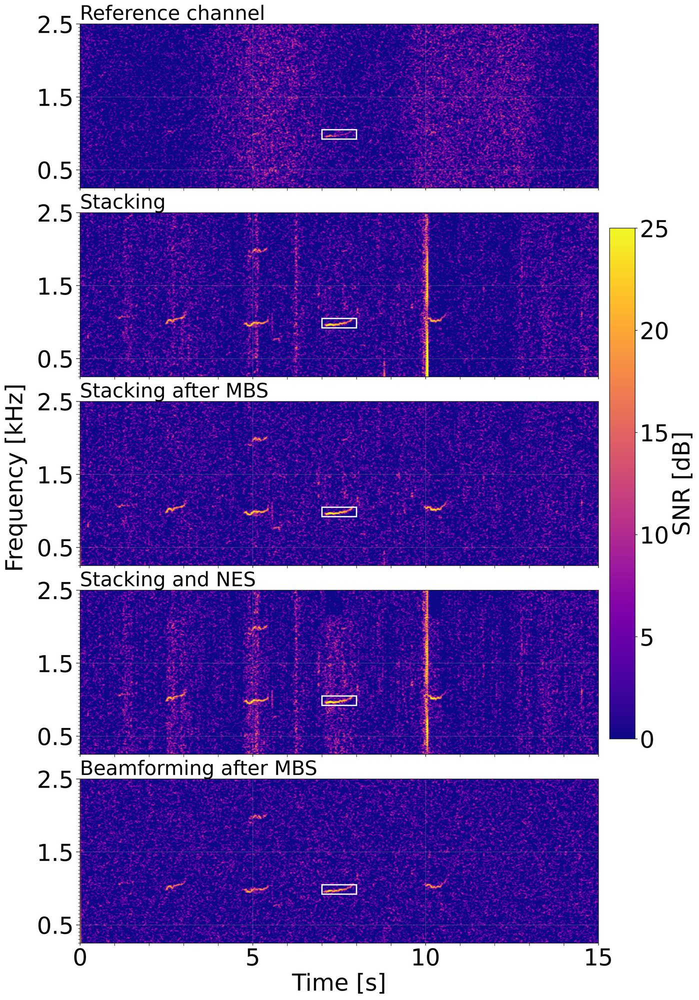

In [11]:
import matplotlib.ticker as ticker
import matplotlib.patches as patches
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 35})

# spec_list = [
#     (f_ref,   t_ref,   SNR_ref_spec,   "1. Reference channel"),
#     (f_pre,   t_pre,   SNR_pre_spec,   "4. MBS (time)"),
#     (f_bis_pre, t_bis_pre, SNR_bis_pre_spec, "6. MBS (frequency)"),
#     (f_hat1d, t_hat1d, SNR_hat1d_spec, "5. NES"),
#     (f_bf,    t_bf,    SNR_bf_spec,    "7. Beamforming with MBS (time)"),
#     # (f_pws,   t_pws,   SNR_pws_spec,   "8. PWS"),
#     # (f_bis_t, t_bis_t, SNR_bis_time_spec, "9. BIS Time"),
#     # (f_loop,  t_loop,  SNR_loop_bis_spec, "10. Loop BIS"),
#     (f_bf,    t_bf,    SNR_bf_bis_spec,  "11. Beamforming with MBS (frequency)")
# ]
spec_list = [
    (f1, t1, SNR1, "1. Reference channel"),
    (f2, t2, SNR2, "2. Stacking"),
    (f3, t3, SNR3, "3. Stacking after MBS"),
    (f4, t4, SNR4, "4. Stacking and NES"),
    # (f5, t5, SNR5, "5. Beamforming (BIS Post-stack)"),
    # (f6, t6, SNR6, "6. Loop Stacked (BIS Pre-stack)"),
    (f7, t7, SNR7, "7. Beamforming after MBS")
]

n_plots = len(spec_list)

fig, axes = plt.subplots(
    n_plots, 1,
    figsize=(15, 5 * n_plots),
    dpi=300,
    sharex=True,
    sharey=True
)

fig.subplots_adjust(hspace=0.15)

if n_plots == 1:
    axes = [axes]

images = []

# t_start = 45
# t_end = 60

y_max = 2500  # Hz

for i, (fp, tp, data, title) in enumerate(spec_list):
    ax = axes[i]

    # -------------------------
    # TIME WINDOW
    # -------------------------
    mask = (tp >= t_start) & (tp <= t_end)
    tp_sub = tp[mask]
    data_sub = data[:, mask]
    t_plot = tp_sub - t_start

    # -------------------------
    # FREQ (Hz → kHz)
    # -------------------------
    fp_khz = fp / 1000

    # vmin, vmax = 0, 25

    im = ax.pcolormesh(
        t_plot, fp_khz, data_sub,
        shading="auto",
        cmap="plasma",
        vmin=vmin,
        vmax=vmax
    )

    # -------------------------
    # X axis
    # -------------------------
    if i == n_plots - 1:
        ax.set_xlabel("Time [s]")

    ax.set_xlim(0, t_end - t_start)

    xticks = np.arange(0, t_end - t_start + 1, 5)
    ax.set_xticks(xticks)

    ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
    ax.tick_params(axis='x', which='minor', length=4)

    # -------------------------
    # WINDOW BOX (FIXED)
    # -------------------------
    if "t_win" in globals() and "f_win" in globals():

        t_win_shifted = (t_win[0] - t_start, t_win[1] - t_start)
        f_win_khz = (f_win[0] / 1000, f_win[1] / 1000)

        ax.add_patch(
            patches.Rectangle(
                (t_win_shifted[0], f_win_khz[0]),
                t_win_shifted[1] - t_win_shifted[0],
                f_win_khz[1] - f_win_khz[0],
                linewidth=2,
                edgecolor='white',
                facecolor='none'
            )
        )

    ax.grid(True, alpha=0.3)

    # -------------------------
    # Y axis (Hz → kHz)
    # -------------------------
    # ax.set_ylim(250 / 1000, y_max / 1000)

    # # yticks = np.arange(0, y_max + 1, 500)

    # # ax.set_yticks(yticks / 1000)
    # # ax.set_yticklabels(yticks / 1000)
    # yticks = np.array([0.5, 1.5, 2.5])

    # ax.set_yticks(yticks)
    # ax.set_yticklabels(yticks)
    # limits (Hz → kHz)
    ax.set_ylim(250/1000, 2500/1000)

    # custom ticks you want
    yticks = np.array([0.5, 1.5, 2.5])

    ax.set_yticks(yticks)
    ax.set_yticklabels(yticks)

    ax.set_yticks(np.arange(250, y_max + 1, 50) / 1000, minor=True)
    ax.tick_params(axis='y', which='minor', length=3)
    ax.tick_params(axis='y', which='major', length=6)

    images.append(im)

    title = title.split(". ", 1)[-1]  # Remove numbering
    ax.set_title(title, loc='left', fontsize=30)
# -------------------------
# SINGLE Y LABEL
# -------------------------
fig.text(
    0.02, 0.5,
    "Frequency [kHz]",
    va="center",
    rotation="vertical"
)

# -------------------------
# COLORBAR
# -------------------------
cbar = fig.colorbar(
    images[-1],
    ax=axes,
    orientation="vertical",
    fraction=0.046,
    pad=0.02
)

cbar.set_label("SNR [dB]")
cbar.ax.yaxis.set_major_formatter('{x:.0f}')

plt.show()

## All events: one figure per panel

Runs the pipeline above (`run_pipeline_for_event`) for every event in `EVENT_CONFIGS`.

In [12]:
EVENT_CONFIGS = {
    "biggs": dict(
        fdir="/mnt/haro_fs/",
        flist_source=['decimator_2026-01-02_23.43.00_UTC_097029.h5'],
        flist_noise=['decimator_2026-01-02_23.40.00_UTC_097026.h5'],
        t_win=(24.5, 25.1), f_win=(950, 1600),
        loop_num=1, c_ref_offset=3,
        event_name="biggs", beam_loops=[1, 2],
        sig_band=[900, 2499], noise_band1=[1, 899], noise_band2=None,
        t_start=12, t_end=27, vmin=0, vmax=20,
    ),
    "humpback": dict(
        fdir="/mnt/nas_das4orcas_onyx/haro-fs/",
        flist_source=['decimator_2025-11-14_09.33.00_UTC_049649.h5'],
        flist_noise=['decimator_2025-11-14_09.20.00_UTC_049636.h5'],
        t_win=(56.5, 57.25), f_win=(900, 1550),
        loop_num=1, c_ref_offset=3,
        event_name="humpback", beam_loops=[[1, 2]],
        sig_band=[300, 1500], noise_band1=[20, 300], noise_band2=[1550, 2499],
        t_start=45, t_end=60, vmin=0, vmax=25,
    ),
    "jpod jan": dict(
        fdir="/mnt/haro_fs/",
        flist_source=['decimator_2026-01-23_21.37.00_UTC_126890.h5'],
        flist_noise=['decimator_2026-01-23_21.30.00_UTC_126883.h5'],
        t_win=(7, 8), f_win=(920, 1050),
        loop_num=2, c_ref=49,
        event_name="jpod jan", beam_loops=[[2, 3]],
        sig_band=[800, 2100], noise_band1=[50, 800], noise_band2=[2100, 2499],
        t_start=0, t_end=15, vmin=0, vmax=25,
    ),
}


def run_pipeline_for_event(cfg):
    """Run the event pipeline above for one `cfg`. Shared settings come from
    the SHARED CALC CONFIG cell."""
    fdir, flist_source, flist_noise = cfg['fdir'], cfg['flist_source'], cfg['flist_noise']
    event_name, loop_num, beam_loops = cfg['event_name'], cfg['loop_num'], cfg['beam_loops']
    sig_band, noise_band1, noise_band2 = cfg['sig_band'], cfg['noise_band1'], cfg.get('noise_band2')
    fiber_length = 2000

    print(f"Analyzing {event_name}...")
    meta = get_h5_metadata(os.path.join(fdir, flist_source[0]))
    fs, dx = meta['fs'], meta['dx']
    source_raw, _ = load_data(fdir, flist_source)
    noise_raw, _ = load_data(fdir, flist_noise)
    source = preprocess(source_raw, fs, lowcut=250)
    noise_file = preprocess(noise_raw, fs, lowcut=250)

    env_data = get_environmental_metadata(os.path.join(fdir, flist_source[0]))
    if env_data:
        print(f"  Tide Height: {env_data['tide_height']:.2f} m, Wind: {env_data['wind_speed']:.1f} km/h")

    loops_f1 = [(120, 142), (144, 203), (271, 296), (443, 465), (630, 660),
                (855, 887), (1091, 1123), (1659, 1722), (1821, 1879)]
    loops_f2 = [(2 * fiber_length - L[1], 2 * fiber_length - L[0]) for L in loops_f1]
    loops = []
    for i in range(8):
        l_group = []
        if 1 in use_fibers: l_group.append(loops_f1[i])
        if 2 in use_fibers: l_group.append(loops_f2[i])
        loops.append(l_group)
    loop_channels = [[(int(L[0] / dx), int(L[1] / dx)) for L in l_group] for l_group in loops]

    c_group = loop_channels[loop_num - 1]
    c_ref = c_group[0][0] + cfg['c_ref_offset'] if 'c_ref_offset' in cfg else cfg['c_ref']

    def get_noise_ref(choice, chan_data):
        src = noise_file if choice == "separate" else source
        if chan_data is None:
            return [src[:, c0:c1] for c0, c1 in c_group]
        return src[:, chan_data]

    sig_block = np.concatenate([source[:, c0:c1] for c0, c1 in c_group], axis=1)
    n_block_concat = np.concatenate(get_noise_ref(noise_config["hat_1d"], None), axis=1)

    if isinstance(beam_loops, list) and len(beam_loops) > 0 and isinstance(beam_loops[0], list):
        beam_loops_clean = beam_loops[0]
    else:
        beam_loops_clean = beam_loops
    ref_loop_idx = int(beam_loops_clean[0])
    target_loops = [int(i) for i in beam_loops_clean[1:]]
    bf_event = event_name.lower()

    def get_enhanced_trace(tr, mbs=True, bis=False):
        f_p, t_p, Zxx_p = stft(tr, fs=fs, nperseg=nperseg, noverlap=noverlap)
        S_log = 10 * np.log10(np.abs(Zxx_p)**2 + 1e-12)
        norm = np.zeros_like(S_log)
        if mbs:
            m_bg = np.nanmedian(S_log, axis=1, keepdims=True)
            norm += m_bg
            if bis:
                norm += np.nanmedian(S_log - m_bg, axis=0, keepdims=True)
        elif bis:
            norm += np.nanmedian(S_log, axis=0, keepdims=True)
        Zxx_norm = Zxx_p * 10**(-norm/20)
        _, tr_rec = istft(Zxx_norm, fs=fs, nperseg=nperseg, noverlap=noverlap)
        return tr_rec[:len(tr)]

    def beamform(data_dict, ref_idx, targets):
        if bf_event not in WHALE_DELAYS:
            print(f"Warning: No delays for {bf_event}, using raw sum.")
            return np.sum([data_dict[i] for i in [ref_idx] + targets], axis=0)
        delays = WHALE_DELAYS[bf_event]
        bf_sig = np.copy(data_dict[ref_idx]).astype(float)
        for i in targets:
            a, b = ref_idx - 1, i - 1
            shift = delays[(a, b)] if (a, b) in delays else (-delays[(b, a)] if (b, a) in delays else None)
            if shift is None:
                print(f"Warning: No delay for ({ref_idx}, {i})"); continue
            shifted = np.roll(data_dict[i], -shift)
            if shift > 0: shifted[-shift:] = 0
            elif shift < 0: shifted[:-shift] = 0
            bf_sig += shifted
        return bf_sig

    data_dict_raw, data_dict_enhanced = {}, {}
    for i in range(1, 9):
        cg = loop_channels[i-1]
        data_dict_raw[i] = np.mean([np.mean(source[:, c0:c1], axis=1) for c0, c1 in cg], axis=0)
        enhanced_fiber_stacks = []
        for c0, c1 in cg:
            enhanced_channels = [get_enhanced_trace(source[:, c], mbs=True, bis=True) for c in range(c0, c1)]
            enhanced_fiber_stacks.append(np.mean(enhanced_channels, axis=0))
        data_dict_enhanced[i] = np.mean(enhanced_fiber_stacks, axis=0)

    tr1_enhanced = get_enhanced_trace(source[:, c_ref], mbs=False, bis=False)
    f1, t1, SNR1 = compute_snr_spectrogram(tr1_enhanced, np.ones((nperseg//2+1, 1)), fs, nperseg, noverlap)
    SNR1 -= np.nanmedian(SNR1, axis=1, keepdims=True)

    tr2_enhanced = get_enhanced_trace(data_dict_raw[loop_num], mbs=False, bis=False)
    f2, t2, SNR2 = compute_snr_spectrogram(tr2_enhanced, np.ones((nperseg//2+1, 1)), fs, nperseg, noverlap)
    SNR2 -= np.nanmedian(SNR2, axis=1, keepdims=True)

    sig_bis_pre = [get_enhanced_trace(sig_block[:, i], mbs=True, bis=True) for i in range(sig_block.shape[1])]
    tr3_enhanced = np.mean(sig_bis_pre, axis=0)
    f3, t3, SNR3 = compute_snr_spectrogram(tr3_enhanced, np.ones((nperseg//2+1, 1)), fs, nperseg, noverlap)
    SNR3 -= np.nanmedian(SNR3, axis=1, keepdims=True)

    b_sig, a_sig = sp.butter(4, sig_band, btype="bandpass", fs=fs)
    b_n1, a_n1 = sp.butter(4, noise_band1, btype="bandpass", fs=fs)
    if noise_band2 is not None:
        b_n2, a_n2 = sp.butter(4, noise_band2, btype="bandpass", fs=fs)
    noise_f1 = sp.filtfilt(b_n1, a_n1, n_block_concat, axis=0)
    if noise_band2 is not None:
        noise_f2 = sp.filtfilt(b_n2, a_n2, n_block_concat, axis=0)
        noise_filt = np.mean(noise_f1 + noise_f2, axis=1)
    else:
        noise_filt = np.mean(noise_f1, axis=1)
    sig_target = np.mean(sp.filtfilt(b_sig, a_sig, sig_block, axis=0), axis=1)
    _, sig_nes = compute_snr_hat(sig_target, noise_filt, window_samples=50, normalize=False,
                                  return_trace=True, gain_power=nes_gain_power)

    tr4_enhanced = get_enhanced_trace(sig_nes, mbs=False, bis=False)
    f4, t4, SNR4 = compute_snr_spectrogram(tr4_enhanced, np.ones((nperseg//2+1, 1)), fs, nperseg, noverlap)
    SNR4 -= np.nanmedian(SNR4, axis=1, keepdims=True)

    tr_bf_pre = beamform(data_dict_enhanced, ref_loop_idx, target_loops)
    tr7_enhanced = get_enhanced_trace(tr_bf_pre, mbs=True, bis=True)
    f7, t7, SNR7 = compute_snr_spectrogram(tr7_enhanced, np.ones((nperseg//2+1, 1)), fs, nperseg, noverlap)
    SNR7 -= np.nanmedian(SNR7, axis=1, keepdims=True)

    gc.collect()

    spec_list = [
        (f1, t1, SNR1, "1. Reference channel"),
        (f2, t2, SNR2, "2. Stacking"),
        (f3, t3, SNR3, "3. Stacking after MBS"),
        (f4, t4, SNR4, "4. Stacking and NES"),
        (f7, t7, SNR7, "7. Beamforming after MBS"),
    ]
    return dict(spec_list=spec_list, t_start=cfg['t_start'], t_end=cfg['t_end'],
                vmin=cfg['vmin'], vmax=cfg['vmax'], t_win=cfg.get('t_win'), f_win=cfg.get('f_win'),
                event_name=event_name)

print(f"{len(EVENT_CONFIGS)} event configs ready: {list(EVENT_CONFIGS.keys())}")

3 event configs ready: ['biggs', 'humpback', 'jpod jan']


In [13]:
def plot_separate_figures(result, suptitle_prefix="", save_dir=None, figure_number=None):
    """One standalone figure per panel, optionally saved as
    Figure<N><letter>.jpeg in save_dir. Only the last panel gets x tick labels."""
    import re
    # Times New Roman to match the paper
    plt.rcParams['font.family'] = 'serif'
    plt.rcParams['font.serif'] = ['Times New Roman', 'Liberation Serif', 'DejaVu Serif']
    spec_list = result['spec_list']
    t_start, t_end = result['t_start'], result['t_end']
    vmin, vmax = result['vmin'], result['vmax']
    t_win, f_win = result.get('t_win'), result.get('f_win')
    event_name = result.get('event_name', 'event')
    y_max = 2500  # Hz
    n_panels = len(spec_list)

    if save_dir:
        os.makedirs(save_dir, exist_ok=True)

    for panel_i, (fp, tp, data, title) in enumerate(spec_list):
        mask = (tp >= t_start) & (tp <= t_end)
        tp_sub = tp[mask]
        data_sub = data[:, mask]
        t_plot = tp_sub - t_start
        fp_khz = fp / 1000

        fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
        im = ax.pcolormesh(t_plot, fp_khz, data_sub, shading="auto", cmap="plasma", vmin=vmin, vmax=vmax)

        if panel_i == n_panels - 1:
            ax.set_xlabel("Time [s]")
        else:
            ax.tick_params(axis='x', which='major', labelbottom=False)
        ax.set_xlim(0, t_end - t_start)
        ax.set_xticks(np.arange(0, t_end - t_start + 1, 5))
        ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
        ax.tick_params(axis='x', which='minor', length=4)

        if t_win is not None and f_win is not None:
            t_win_shifted = (t_win[0] - t_start, t_win[1] - t_start)
            f_win_khz = (f_win[0] / 1000, f_win[1] / 1000)
            ax.add_patch(patches.Rectangle(
                (t_win_shifted[0], f_win_khz[0]),
                t_win_shifted[1] - t_win_shifted[0],
                f_win_khz[1] - f_win_khz[0],
                linewidth=2, edgecolor='white', facecolor='none'))

        ax.grid(True, alpha=0.3)
        ax.set_ylim(250/1000, y_max/1000)
        yticks = np.array([0.5, 1.5, 2.5])
        ax.set_yticks(yticks)
        ax.set_yticklabels(yticks)
        ax.set_yticks(np.arange(250, y_max + 1, 50) / 1000, minor=True)
        ax.tick_params(axis='y', which='minor', length=3)
        ax.tick_params(axis='y', which='major', length=6)
        ax.set_ylabel("Frequency [kHz]")

        clean_title = title.split(". ", 1)[-1]
        ax.set_title(f"{clean_title}", loc='left', fontsize=30)

        cbar = fig.colorbar(im, ax=ax, orientation="vertical", fraction=0.046, pad=0.02)
        cbar.set_label("SNR [dB]")
        # 5 evenly spaced ticks, rounded labels
        cbar_ticks = np.linspace(vmin, vmax, 5)
        cbar.set_ticks(cbar_ticks)
        cbar.set_ticklabels([f'{t:.0f}' for t in cbar_ticks])

        plt.tight_layout()

        if save_dir:
            if figure_number is not None:
                letter = chr(ord('a') + panel_i)
                fname = f"Figure{figure_number}{letter}.jpeg"
            else:
                panel_num = title.split(".", 1)[0].strip()
                safe_event = re.sub(r'[^A-Za-z0-9_-]+', '_', event_name).strip('_')
                safe_title = re.sub(r'[^A-Za-z0-9_-]+', '_', clean_title).strip('_')
                fname = f"{safe_event}_{panel_num}_{safe_title}.jpeg"
            fig.savefig(os.path.join(save_dir, fname), format='jpeg', dpi=300)

        plt.show()

print("plot_separate_figures ready")

plot_separate_figures ready


In [14]:
all_results = {}
for name, cfg in EVENT_CONFIGS.items():
    print(f"\n=== {name} ===")
    all_results[name] = run_pipeline_for_event(cfg)
print("\nall_results ready:", list(all_results.keys()))


=== biggs ===
Analyzing biggs...


  Tide Height: 1.69 m, Wind: nan km/h

=== humpback ===
Analyzing humpback...
  Tide Height: 1.14 m, Wind: nan km/h

=== jpod jan ===
Analyzing jpod jan...
  Tide Height: 1.20 m, Wind: nan km/h

all_results ready: ['biggs', 'humpback', 'jpod jan']


### Plot all events

Uses cached `all_results`.


--- biggs: separate figures ---


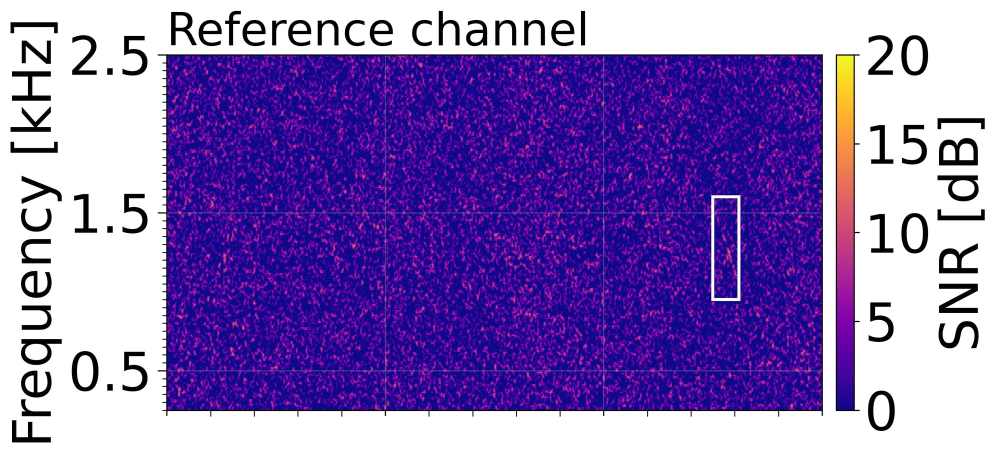

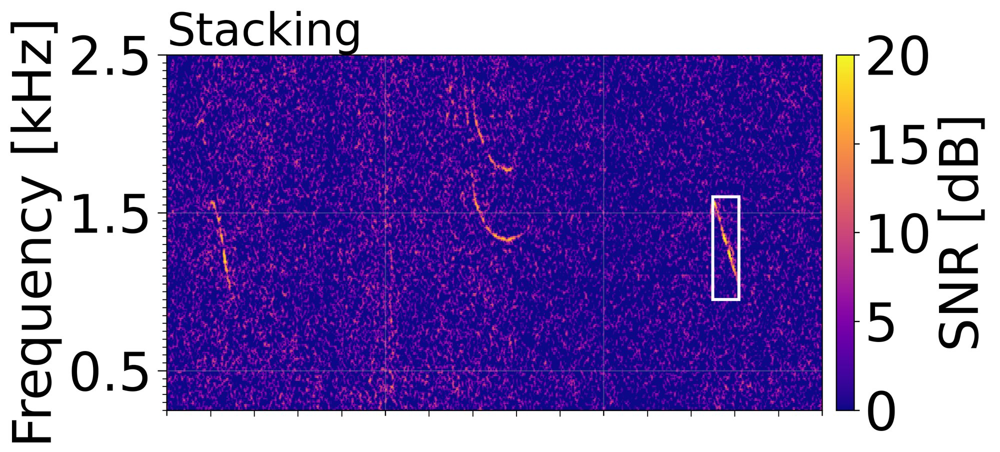

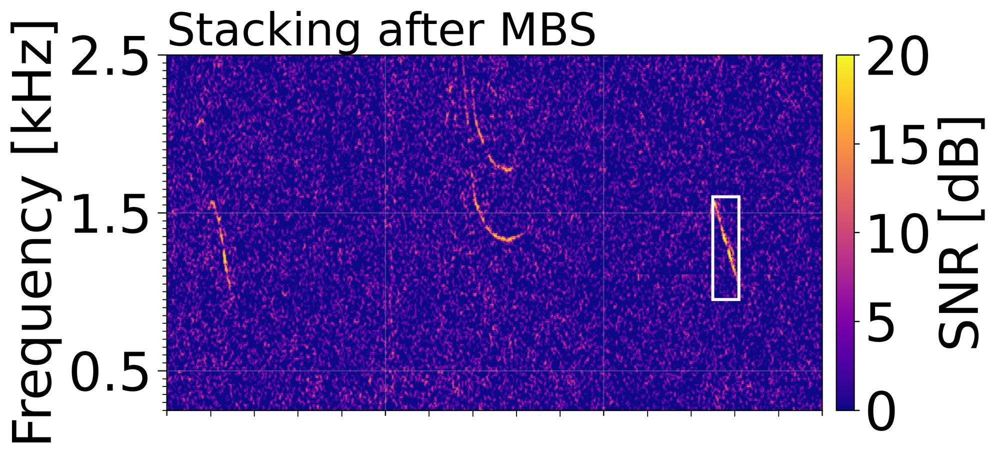

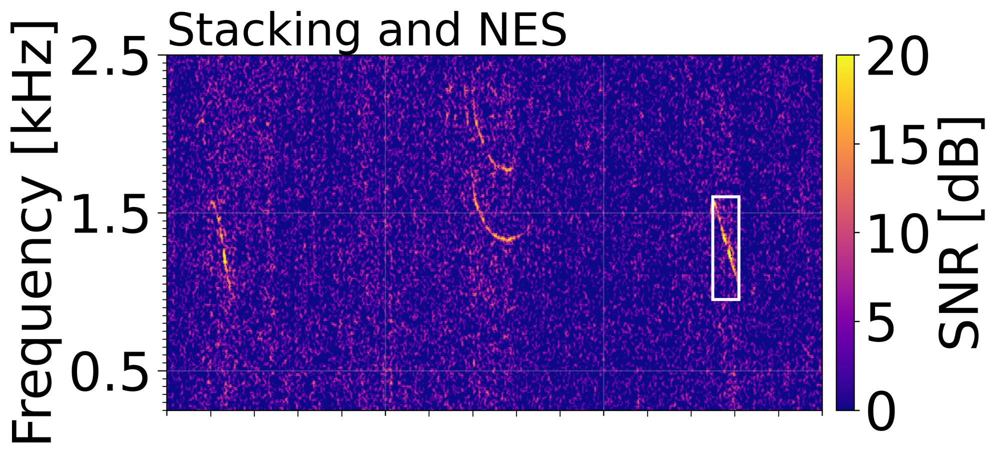

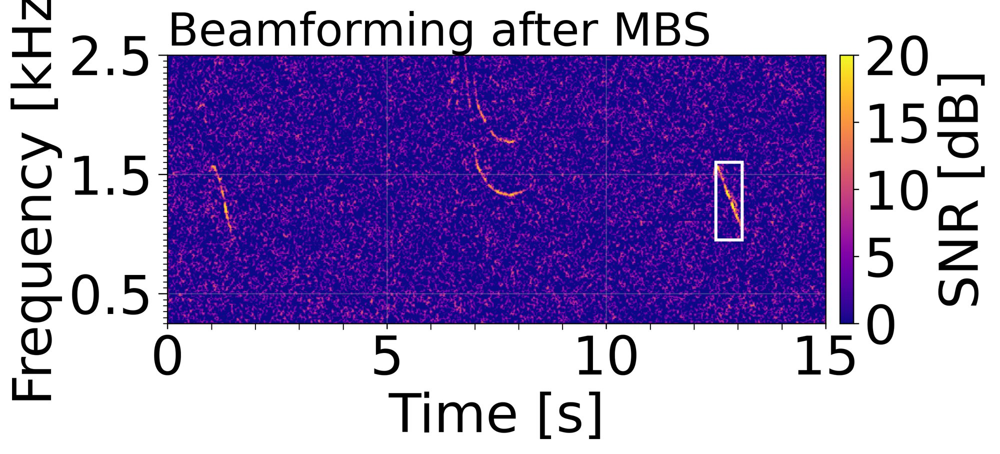


--- humpback: separate figures ---


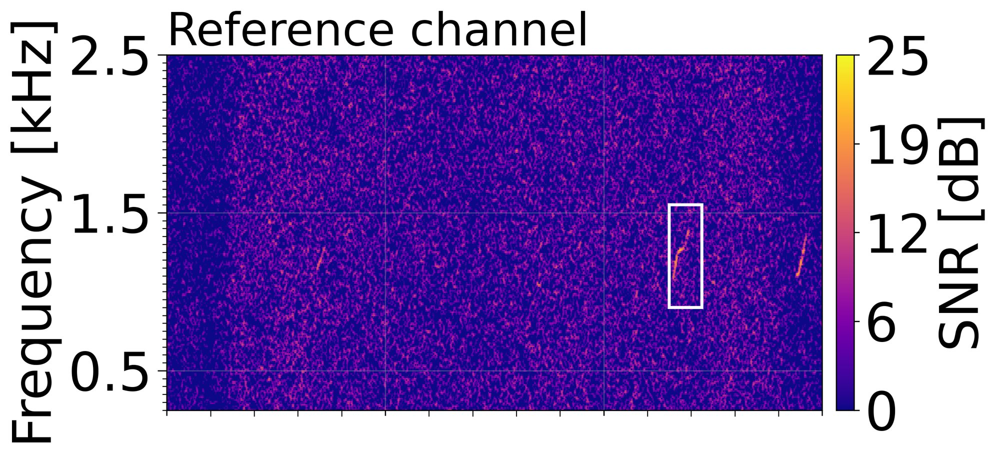

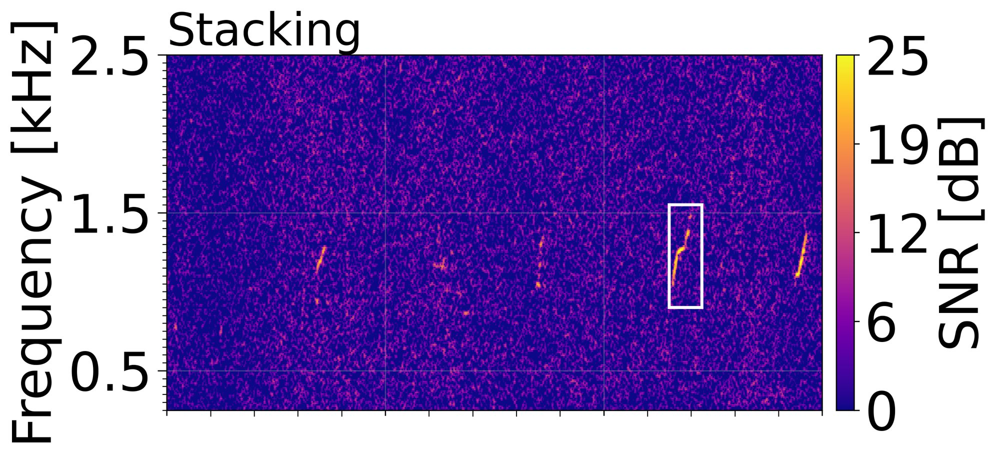

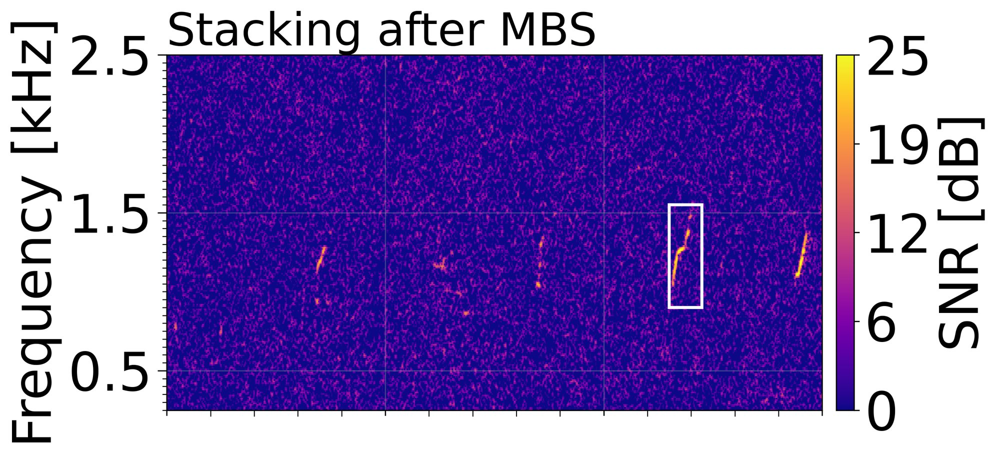

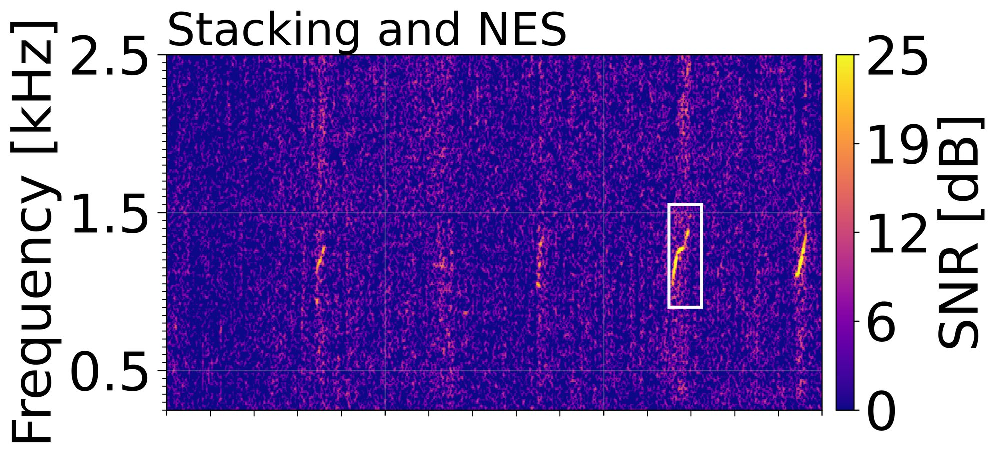

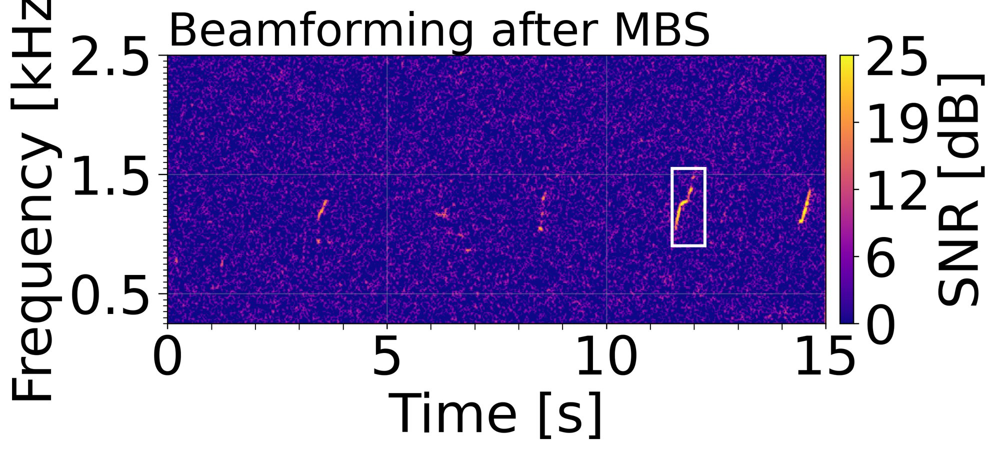


--- jpod jan: separate figures ---


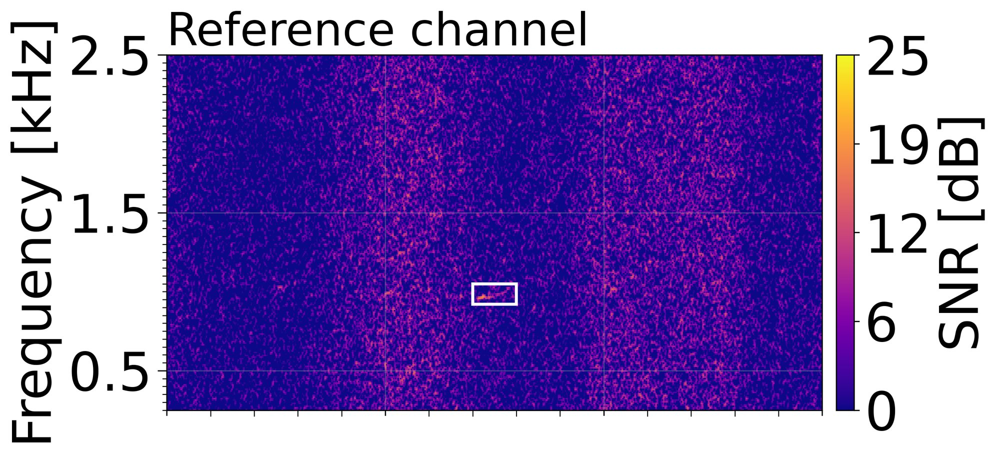

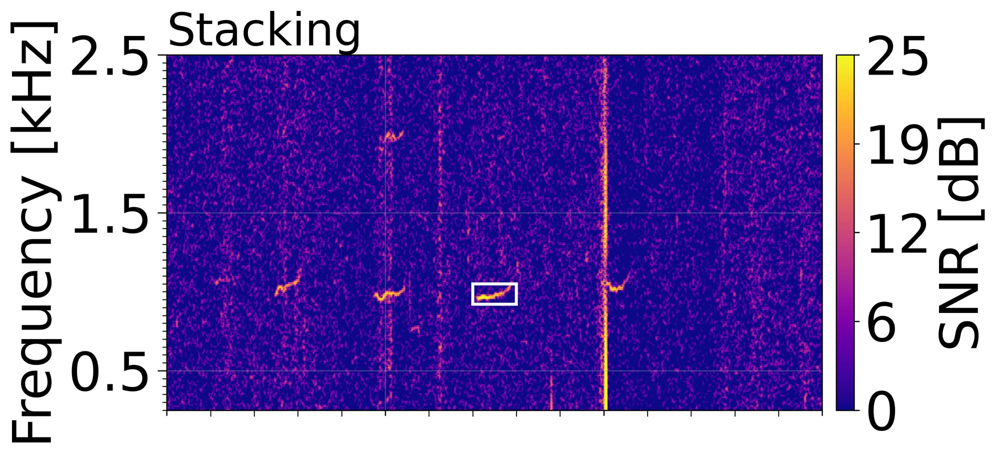

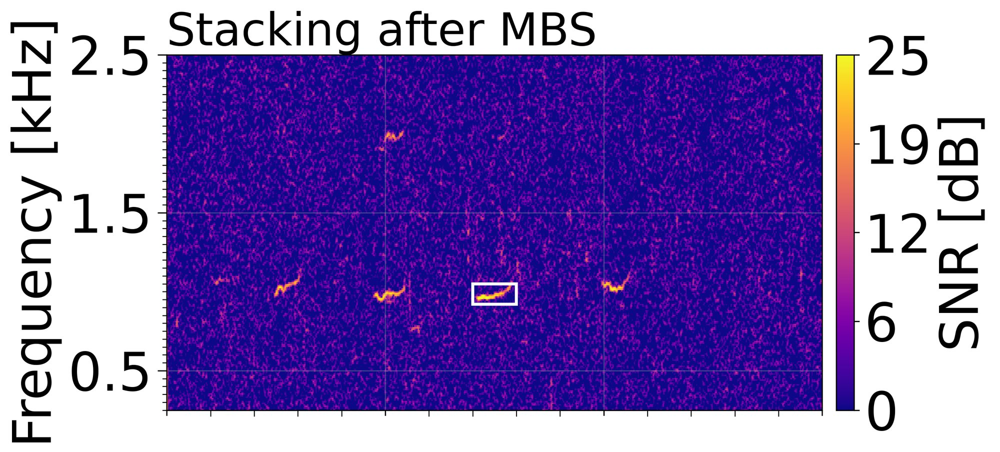

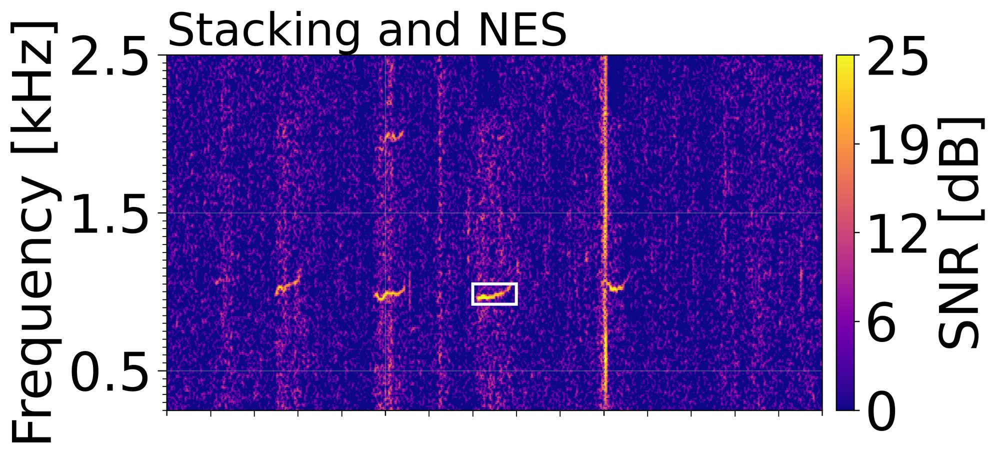

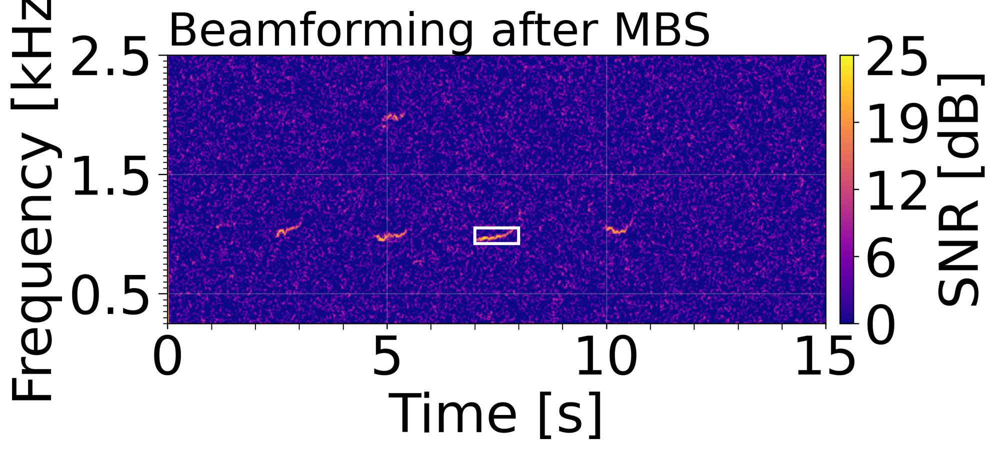


saved .jpeg figures to /home/sam/gemini/separate_figures/


In [15]:
SEPARATE_FIGURES_DIR = "separate_figures"

# Manuscript figure numbers ("jpod jan" = SRKW)
EVENT_FIGURE_NUM = {"humpback": 8, "biggs": 9, "jpod jan": 10}

for name, result in all_results.items():
    print(f"\n--- {name}: separate figures ---")
    plot_separate_figures(result, suptitle_prefix=f"[{name}] ", save_dir=SEPARATE_FIGURES_DIR,
                           figure_number=EVENT_FIGURE_NUM.get(name))

print(f"\nsaved .jpeg figures to {os.path.abspath(SEPARATE_FIGURES_DIR)}/")

### Combined multi-panel figure per event

Panels labelled (a)–(e). Uses cached `all_results`.

In [16]:
import matplotlib.font_manager as font_manager


def plot_combined_figure(result, save_path=None, panel_labels=True):
    """Stacked SNR spectrograms for one event with shared axes and colorbar,
    panels tagged (a), (b), ... Saved to save_path if given."""
    spec_list = result['spec_list']
    t_start, t_end = result['t_start'], result['t_end']
    vmin, vmax = result['vmin'], result['vmax']
    t_win, f_win = result.get('t_win'), result.get('f_win')
    y_max = 2500  # Hz

    plt.rcParams.update({'font.size': 35})
    n_plots = len(spec_list)

    fig, axes = plt.subplots(
        n_plots, 1,
        figsize=(15, 6.2 * n_plots),
        dpi=300,
        sharex=True,
        sharey=True,
    )
    fig.subplots_adjust(hspace=0.28 if panel_labels else 0.15)
    if n_plots == 1:
        axes = [axes]

    images = []
    for i, (fp, tp, data, title) in enumerate(spec_list):
        ax = axes[i]

        mask = (tp >= t_start) & (tp <= t_end)
        tp_sub = tp[mask]
        data_sub = data[:, mask]
        t_plot = tp_sub - t_start
        fp_khz = fp / 1000

        im = ax.pcolormesh(
            t_plot, fp_khz, data_sub,
            shading="auto", cmap="plasma", vmin=vmin, vmax=vmax,
        )

        # X axis
        if i == n_plots - 1:
            ax.set_xlabel("Time [s]")
        ax.set_xlim(0, t_end - t_start)
        ax.set_xticks(np.arange(0, t_end - t_start + 1, 5))
        ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
        ax.tick_params(axis='x', which='minor', length=4)

        # Target window box
        if t_win is not None and f_win is not None:
            t_win_shifted = (t_win[0] - t_start, t_win[1] - t_start)
            f_win_khz = (f_win[0] / 1000, f_win[1] / 1000)
            ax.add_patch(patches.Rectangle(
                (t_win_shifted[0], f_win_khz[0]),
                t_win_shifted[1] - t_win_shifted[0],
                f_win_khz[1] - f_win_khz[0],
                linewidth=2, edgecolor='white', facecolor='none',
            ))

        ax.grid(True, alpha=0.3)

        # Y axis (Hz -> kHz)
        ax.set_ylim(250 / 1000, 2500 / 1000)
        yticks = np.array([0.5, 1.5, 2.5])
        ax.set_yticks(yticks)
        ax.set_yticklabels(yticks)
        ax.set_yticks(np.arange(250, y_max + 1, 50) / 1000, minor=True)
        ax.tick_params(axis='y', which='minor', length=3)
        ax.tick_params(axis='y', which='major', length=6)

        images.append(im)

        ax.set_title(title.split(". ", 1)[-1], loc='left', fontsize=30)

        # Panel letter below the axes (lower on the bottom panel to clear the x label)
        if panel_labels:
            letter = chr(ord('a') + i)
            y_off = -0.36 if i == n_plots - 1 else -0.055
            letter_font = font_manager.FontProperties(
                family=['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
                weight='bold', size=32)
            ax.text(0.5, y_off, f"({letter})", transform=ax.transAxes,
                    ha='center', va='top', fontproperties=letter_font)

    fig.text(0.02, 0.5, "Frequency [kHz]", va="center", rotation="vertical")

    cbar = fig.colorbar(
        images[-1], ax=axes, orientation="vertical",
        fraction=0.046, pad=0.02,
    )
    cbar.set_label("SNR [dB]")
    cbar.ax.yaxis.set_major_formatter('{x:.0f}')

    if save_path:
        d = os.path.dirname(save_path)
        if d:
            os.makedirs(d, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()


print("plot_combined_figure ready")


plot_combined_figure ready



--- biggs: combined figure ---


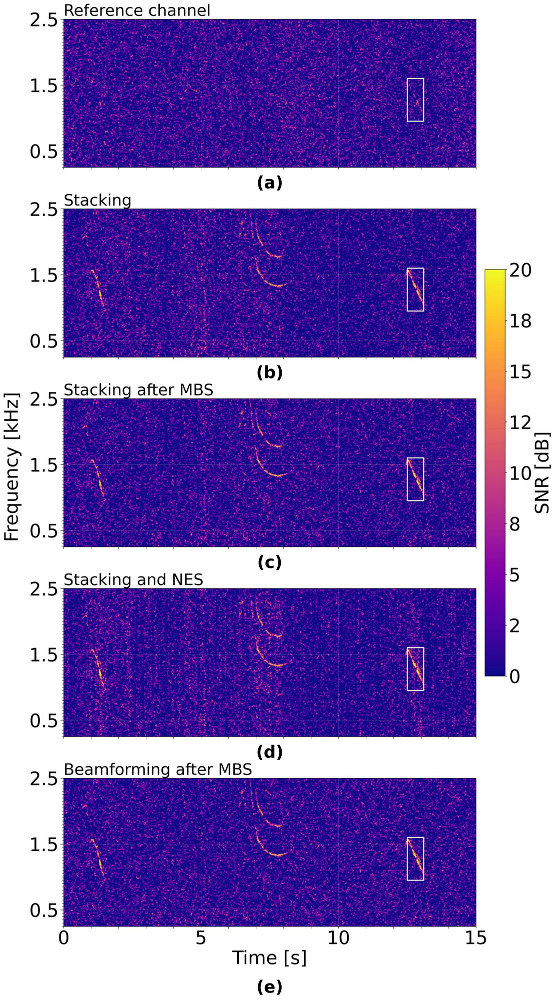


--- humpback: combined figure ---


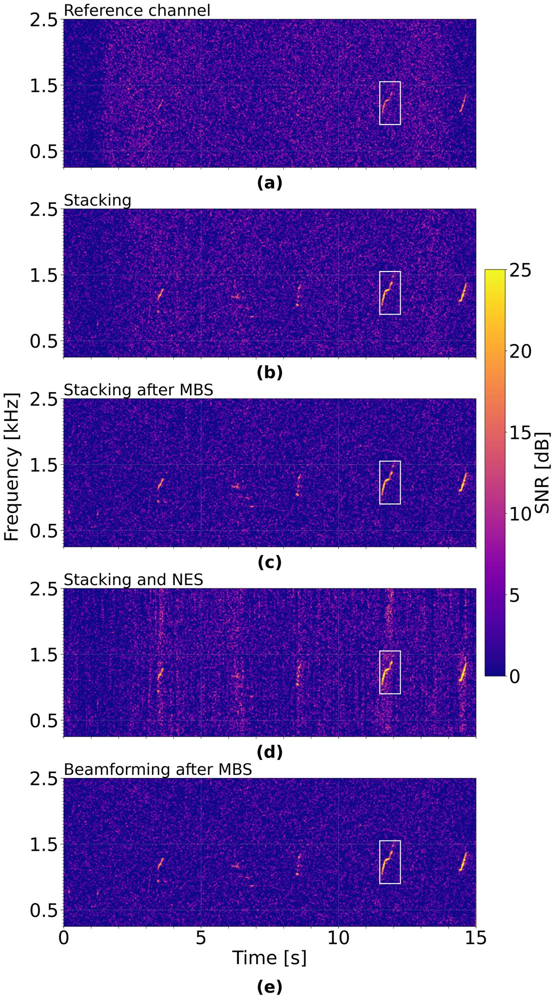


--- jpod jan: combined figure ---


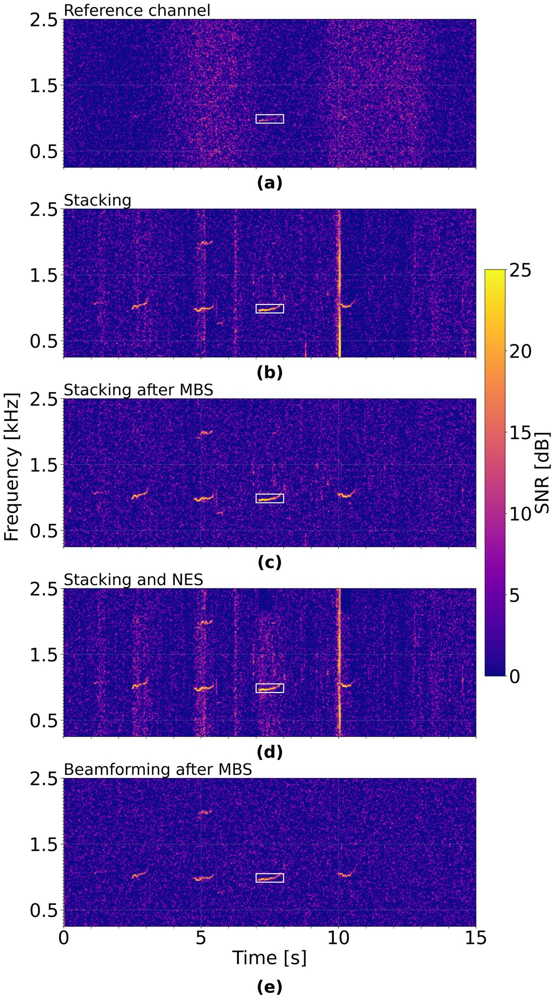


saved combined figures to /home/sam/gemini/combined_event_figures/


In [17]:
COMBINED_FIGURES_DIR = "combined_event_figures"

for name, result in all_results.items():
    print(f"\n--- {name}: combined figure ---")
    fig_num = EVENT_FIGURE_NUM.get(name)
    save_path = (os.path.join(COMBINED_FIGURES_DIR, f"Figure{fig_num}.jpeg")
                 if fig_num is not None else
                 os.path.join(COMBINED_FIGURES_DIR, f"{name.replace(' ', '_')}.jpeg"))
    plot_combined_figure(result, save_path=save_path)

print(f"\nsaved combined figures to {os.path.abspath(COMBINED_FIGURES_DIR)}/")


## Straight-fiber sections next to each loop

Stacks `STRAIGHT_N_CHAN` straight-fiber channels on each side of each loop (fiber 1) to check
whether calls are detected off the coiled sections. Windows are kept `STRAIGHT_GAP` channels from
any loop and shifted outward past a neighbouring loop if needed (tagged `[shifted past neighbour]`).

In [18]:
# ---- straight-section geometry knobs ----
STRAIGHT_N_CHAN = 6   # channels stacked on each side of a loop
STRAIGHT_GAP = 3      # channels kept clear of any loop


def find_straight_window(loop_span, side, obstructions, nx,
                         n_chan=STRAIGHT_N_CHAN, gap=STRAIGHT_GAP):
    """Channel window of `n_chan` straight-fiber channels beside a loop.

    loop_span    : (c0, c1) of the loop.
    side         : "before" (lower channels) or "after" (higher).
    obstructions : (c0, c1) of every loop; the window stays `gap` channels clear.

    Returns (start, end, shifted) for the slice [start, end), or None if it runs
    off the fiber. `shifted` is True if it was pushed past a neighbouring loop.
    """
    c0, c1 = loop_span
    others = [s for s in obstructions if s != loop_span]

    def hit(s, e):
        for (lc0, lc1) in others:
            if s < lc1 + gap and e > lc0 - gap:      # intersects within the gap
                return (lc0, lc1)
        return None

    shifted = False
    if side == "before":
        e = c0 - gap
        s = e - n_chan
        while s >= 0:
            h = hit(s, e)
            if h is None:
                return (s, e, shifted)
            shifted = True
            e = h[0] - gap
            s = e - n_chan
        return None
    else:  # "after"
        s = c1 + gap
        e = s + n_chan
        while e <= nx:
            h = hit(s, e)
            if h is None:
                return (s, e, shifted)
            shifted = True
            s = h[1] + gap
            e = s + n_chan
        return None


def run_straight_sections_for_event(cfg):
    """Before/after straight-fiber MBS spectrograms for each of the 8 loops."""
    fdir, flist_source = cfg['fdir'], cfg['flist_source']

    meta = get_h5_metadata(os.path.join(fdir, flist_source[0]))
    fs, dx, nx = meta['fs'], meta['dx'], meta['nx']
    source_raw, _ = load_data(fdir, flist_source)
    source = preprocess(source_raw, fs, lowcut=250)

    loops_f1 = [(120, 142), (144, 203), (271, 296), (443, 465), (630, 660),
                (855, 887), (1091, 1123), (1659, 1722), (1821, 1879)]
    # all 9 coil spans block windows; only the first 8 get their own panels
    obstructions = [(int(a / dx), int(b / dx)) for a, b in loops_f1]
    loop_spans = obstructions[:8]

    panels = []
    for k, span in enumerate(loop_spans, start=1):
        for side in ("before", "after"):
            entry = dict(loop=k, side=side, span=span)
            win = find_straight_window(span, side, obstructions, nx)
            if win is None:
                entry['window'] = None
                panels.append(entry)
                continue
            s, e, shifted = win
            stack = source[:, s:e].mean(axis=1)
            f, t, S = compute_snr_spectrogram(
                stack, np.ones((nperseg // 2 + 1, 1)), fs, nperseg, noverlap)
            S -= np.nanmedian(S, axis=1, keepdims=True)
            entry.update(window=(s, e), shifted=shifted, f=f, t=t, S=S)
            panels.append(entry)

    del source, source_raw
    gc.collect()
    return dict(event_name=cfg['event_name'], panels=panels, dx=dx,
                t_start=cfg['t_start'], t_end=cfg['t_end'],
                vmin=cfg['vmin'], vmax=cfg['vmax'],
                t_win=cfg.get('t_win'), f_win=cfg.get('f_win'))


straight_results = {}
for _name, _cfg in EVENT_CONFIGS.items():
    print(f"\n=== {_name}: straight sections ===")
    straight_results[_name] = run_straight_sections_for_event(_cfg)
print("\nstraight_results ready:", list(straight_results.keys()))



=== biggs: straight sections ===



=== humpback: straight sections ===

=== jpod jan: straight sections ===

straight_results ready: ['biggs', 'humpback', 'jpod jan']



--- biggs: straight-section grid ---


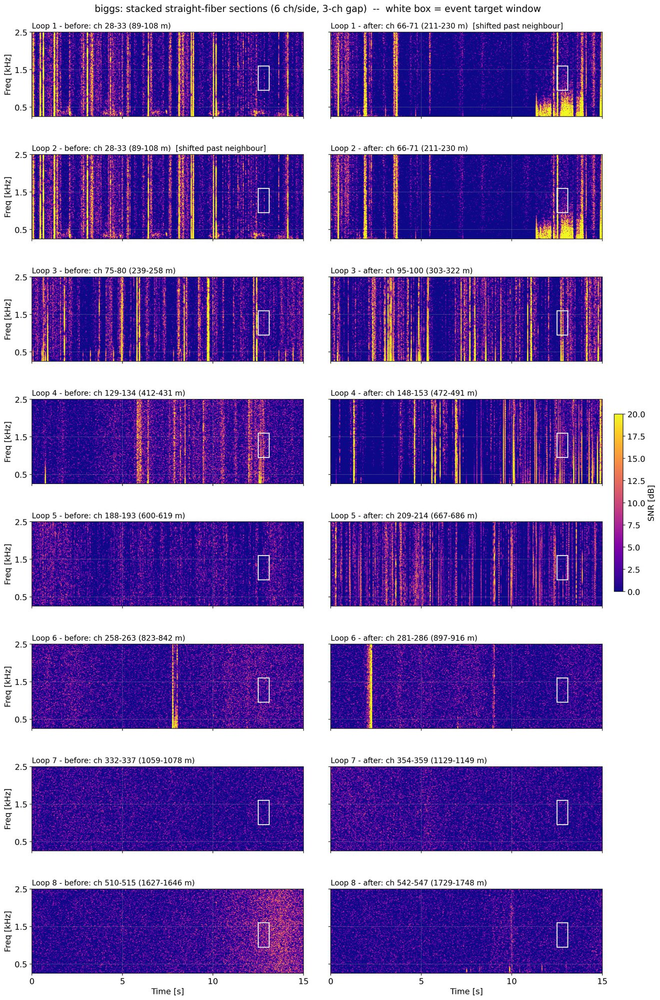


--- humpback: straight-section grid ---


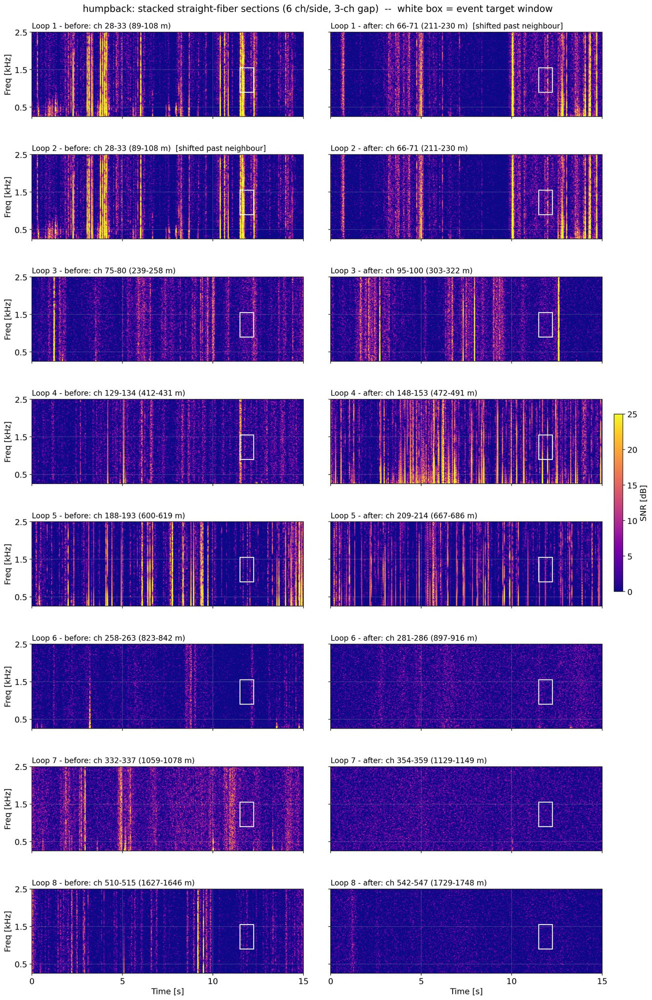


--- jpod jan: straight-section grid ---


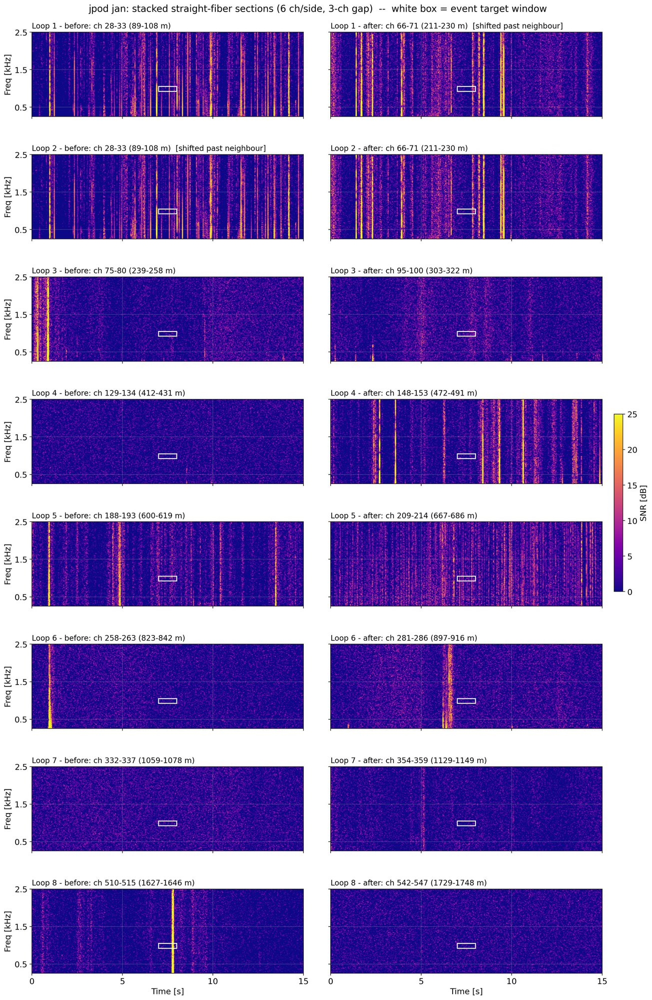


saved to /home/sam/gemini/straight_section_figures/


In [19]:
def plot_straight_sections_grid(result, save_path=None):
    """8 loops x 2 columns (before / after) grid of stacked straight-fiber
    MBS spectrograms for one event, shared axes, one colorbar."""
    panels = result['panels']
    t_start, t_end = result['t_start'], result['t_end']
    vmin, vmax = result['vmin'], result['vmax']
    t_win, f_win = result.get('t_win'), result.get('f_win')
    dx = result['dx']
    y_max = 2500  # Hz

    n_loops = max(p['loop'] for p in panels)
    col = {"before": 0, "after": 1}

    plt.rcParams.update({'font.size': 13})
    fig, axes = plt.subplots(
        n_loops, 2, figsize=(17, 3.1 * n_loops), dpi=200,
        sharex=True, sharey=True, squeeze=False)
    fig.subplots_adjust(hspace=0.45, wspace=0.1, top=0.955, right=0.9)

    im = None
    for p in panels:
        ax = axes[p['loop'] - 1][col[p['side']]]

        if p['window'] is None:
            ax.text(0.5, 0.5, "no clean straight fiber\n(runs off fiber end)",
                    ha='center', va='center', transform=ax.transAxes, fontsize=11)
            ax.set_title(f"Loop {p['loop']} - {p['side']}", loc='left', fontsize=12)
            continue

        f, t, S = p['f'], p['t'], p['S']
        m = (t >= t_start) & (t <= t_end)
        im = ax.pcolormesh(t[m] - t_start, f / 1000, S[:, m],
                           shading="auto", cmap="plasma", vmin=vmin, vmax=vmax)

        if t_win is not None and f_win is not None:
            ax.add_patch(patches.Rectangle(
                (t_win[0] - t_start, f_win[0] / 1000),
                t_win[1] - t_win[0], (f_win[1] - f_win[0]) / 1000,
                linewidth=1.5, edgecolor='white', facecolor='none'))

        ax.set_xlim(0, t_end - t_start)
        ax.set_xticks(np.arange(0, t_end - t_start + 1, 5))
        ax.set_ylim(250 / 1000, y_max / 1000)
        ax.set_yticks([0.5, 1.5, 2.5])
        ax.grid(True, alpha=0.3)

        s, e = p['window']
        tag = "  [shifted past neighbour]" if p['shifted'] else ""
        ax.set_title(
            f"Loop {p['loop']} - {p['side']}: ch {s}-{e - 1} "
            f"({s * dx:.0f}-{e * dx:.0f} m){tag}", loc='left', fontsize=12)

    for ax in axes[-1]:
        ax.set_xlabel("Time [s]")
    for row in axes:
        row[0].set_ylabel("Freq [kHz]")

    fig.suptitle(
        f"{result['event_name']}: stacked straight-fiber sections "
        f"({STRAIGHT_N_CHAN} ch/side, {STRAIGHT_GAP}-ch gap)  --  "
        f"white box = event target window", fontsize=15)

    if im is not None:
        cbar = fig.colorbar(im, ax=axes.ravel().tolist(),
                            orientation="vertical", fraction=0.015, pad=0.02)
        cbar.set_label("SNR [dB]")

    if save_path:
        d = os.path.dirname(save_path)
        if d:
            os.makedirs(d, exist_ok=True)
        fig.savefig(save_path, dpi=200, bbox_inches='tight')

    plt.show()


STRAIGHT_FIGURES_DIR = "straight_section_figures"
for _name, _result in straight_results.items():
    print(f"\n--- {_name}: straight-section grid ---")
    _safe = _name.replace(' ', '_')
    plot_straight_sections_grid(
        _result, save_path=os.path.join(STRAIGHT_FIGURES_DIR, f"{_safe}_straight_sections.jpeg"))
print(f"\nsaved to {os.path.abspath(STRAIGHT_FIGURES_DIR)}/")


In [20]:
# from scipy.fft import fft2, fftshift, fftfreq

# # =========================================================
# # F-K Plot with Bandpass and Velocity (Sound Speed) Filter
# # =========================================================
# # 1. Filter & Visualization Parameters
# f_band_fk = (0.01, 2.5)    # Hz (Bandpass filter range)
# v_sound = 1500             # m/s (Speed of sound in water)
# v_tol = 400                # m/s (Velocity filter tolerance - widen if plot is too empty)
# apply_fk_filter = False    # Set to True to isolate signals matching sound speed

# # --- Adjust Power Ranges (dB) here ---
# vmin_fk1, vmax_fk1 = 10, 50    # Range for Panel 1 (Full Frequency)
# vmin_fk2, vmax_fk2 = 10, 40    # Range for Panel 2 (Low Frequency Zoom)

# # Pro-tip: Use percentiles if data ranges vary significantly:
# # vmin_fk1, vmax_fk1 = np.nanpercentile(fk_pwr, 10), np.nanpercentile(fk_pwr, 99)

# # 2. Window Selection
# t_win_fk = (11, 13)        # seconds
# d_win_fk = (120, 203)      # meters

# # Convert distance to channel indices
# c0_fk, c1_fk = int(d_win_fk[0] / dx), int(d_win_fk[1] / dx)
# it0, it1 = int(max(0, t_win_fk[0] * fs)), int(min(source_raw.shape[0], t_win_fk[1] * fs))

# # Extract raw data and ensure it's finite (Fixes ValueError with NaNs)
# data_fk_raw = source_raw[it0:it1, c0_fk:c1_fk].astype(float)
# data_fk_raw = np.nan_to_num(data_fk_raw, nan=0.0, posinf=0.0, neginf=0.0)

# # 3. Apply Bandpass Filter
# if f_band_fk:
#     b_fk, a_fk = sp.butter(4, f_band_fk, btype='bandpass', fs=fs)
#     data_fk_raw = sp.filtfilt(b_fk, a_fk, data_fk_raw, axis=0)

# # Detrending
# data_fk_raw = detrend(data_fk_raw, axis=1)
# data_fk_raw = detrend(data_fk_raw, axis=0)

# nt, nx = data_fk_raw.shape
# n_fft_t = int(2**np.ceil(np.log2(nt)) * 16) 
# n_fft_k = int(2**np.ceil(np.log2(nx)) * 8)

# fk_full = fftshift(fft2(data_fk_raw, s=(n_fft_t, n_fft_k)))
# f_vec = fftshift(fftfreq(n_fft_t, 1/fs))
# k_vec = fftshift(fftfreq(n_fft_k, dx))
# fk_pwr = 10 * np.log10(np.abs(fk_full)**2 + 1e-12)

# # 4. Apply F-K (Velocity) Filter
# if apply_fk_filter:
#     K_grid, F_grid = np.meshgrid(k_vec, f_vec)
#     # Velocity V = F / K
#     V_grid = np.divide(F_grid, K_grid, out=np.zeros_like(F_grid), where=K_grid!=0)
#     mask = (np.abs(V_grid) >= v_sound - v_tol) & (np.abs(V_grid) <= v_sound + v_tol)
#     # Set excluded areas to just below the floor of the plot
#     fk_pwr = np.where(mask, fk_pwr, min(vmin_fk1, vmin_fk2) - 10) 

# fig, axes = plt.subplots(1, 2, figsize=(20, 8), dpi=200)

# # Panel 1: Full Sampled Frequency
# im0 = axes[0].imshow(fk_pwr, 
#                      extent=[k_vec[0], k_vec[-1], f_vec[0], f_vec[-1]], 
#                      aspect='auto', origin='lower', cmap='magma', 
#                      interpolation='bilinear',
#                      vmin=vmin_fk1, vmax=vmax_fk1)
# axes[0].set_title(f'F-K Plot (Filtered) - Dist: {d_win_fk[0]}-{d_win_fk[1]}m')
# axes[0].set_xlabel('Wavenumber [1/m]')
# axes[0].set_ylabel('Frequency [Hz]')
# fig.colorbar(im0, ax=axes[0], label='Power [dB]')

# # Panel 2: Low Frequency (0.01 - 1 Hz Zoom)
# im1 = axes[1].imshow(fk_pwr, 
#                      extent=[k_vec[0], k_vec[-1], f_vec[0], f_vec[-1]], 
#                      aspect='auto', origin='lower', cmap='magma', 
#                      interpolation='bilinear', 
#                      vmin=vmin_fk2, vmax=vmax_fk2)
# axes[1].set_ylim(0.01, 1.0)
# axes[1].set_title(f'F-K Plot (0.01 - 1 Hz Zoom)')
# axes[1].set_xlabel('Wavenumber [1/m]')
# axes[1].set_ylabel('Frequency [Hz]')
# fig.colorbar(im1, ax=axes[1], label='Power [dB]')

# plt.tight_layout()
# plt.show()

In [21]:
def get_metrics(f, t, spec, f_w, t_w): 
    fi = np.where((f >= f_w[0]) & (f <= f_w[1]))[0]
    ti = np.where((t >= t_w[0]) & (t <= t_w[1]))[0]
    if len(fi) == 0 or len(ti) == 0: return np.nan, np.nan
    data_win = spec[np.ix_(fi, ti)]
    return np.nanpercentile(data_win, 100), np.nanmedian(data_win)

print(f"\n--- SNR Summary for {current_event} (Window: {t_win[0]}-{t_win[1]}s, {f_win[0]}-{f_win[1]}Hz) ---")
print(f"{'Method':<40}  {'Peak SNR':<12}")
print("-" * 70)
for f, t, data, title in spec_list:
    peak, med = get_metrics(f, t, data, f_win, t_win)
    print(f"{title:<40}  {peak:8.1f} dB")


--- SNR Summary for jpod jan (Window: 7-8s, 920-1050Hz) ---
Method                                    Peak SNR    
----------------------------------------------------------------------
1. Reference channel                          18.7 dB
2. Stacking                                   28.2 dB
3. Stacking after MBS                         29.4 dB
4. Stacking and NES                           30.8 dB
7. Beamforming after MBS                      25.0 dB
